# LAB 09 — Bias, Variance and Imbalanced Data
## Student Information
Name: Zohaib Khan

Student ID: 023-24-0217

Section: G

GitHub: https://github.com/Zohaib-Khan-Chandio/Machine-Learning-labs

Kaggle: https://www.kaggle.com/zohaibkhanchandio

Dataset Source: https://www.kaggle.com/datasets/fedesoriano/stroke-prediction

Dataset: healthcare-dataset-stroke-data_1.csv

In [1]:
from google.colab import files
uploaded = files.upload()

Saving healthcare-dataset-stroke-data_1.csv to healthcare-dataset-stroke-data_1.csv


# Part0  Setup and the Data

In [2]:
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import validation_curve
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

In [3]:
# Load the dataset and explore it
df = pd.read_csv('healthcare-dataset-stroke-data_1.csv')

print("Dataset Shape:", df.shape)

missing_cols = df.columns[df.isnull().any()].tolist()
print("Columns with missing values:", missing_cols)
print("Missing counts per column:\n", df[missing_cols].isnull().sum())

print("\nGender Value Counts:")
print(df['gender'].value_counts())

stroke_counts = df['stroke'].value_counts()
stroke_percentages = df['stroke'].value_counts(normalize=True) * 100

print("\nStroke Target Counts:")
print(stroke_counts)
print("\nStroke Target Percentages:")
print(stroke_percentages.map("{:.2f}%".format))

Dataset Shape: (5110, 12)
Columns with missing values: ['bmi']
Missing counts per column:
 bmi    201
dtype: int64

Gender Value Counts:
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

Stroke Target Counts:
stroke
0    4861
1     249
Name: count, dtype: int64

Stroke Target Percentages:
stroke
0    95.13%
1     4.87%
Name: proportion, dtype: object


In [4]:
# rough
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [5]:
df = df.drop(columns=['id'])
df = df[df['gender'] != 'Other']
df = pd.get_dummies(df, drop_first=True)

In [6]:
# train test split
X = df.drop(columns=['stroke'])
y = df['stroke']

X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.20, stratify=y, random_state=42 )

bmi_median = X_train['bmi'].median()

X_train['bmi'] = X_train['bmi'].fillna(bmi_median)
X_test['bmi'] = X_test['bmi'].fillna(bmi_median)

scaler = StandardScaler()

# List of numerical columns to scale
num_cols = ['age', 'avg_glucose_level', 'bmi']

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

In [7]:
print("--- Training Set ---")
print("Total rows:", len(y_train))
print("Stroke = 1:", (y_train == 1).sum())
print("Stroke = 0:", (y_train == 0).sum())

print("\n--- Test Set ---")
print("Total rows:", len(y_test))
print("Stroke = 1:", (y_test == 1).sum())
print("Stroke = 0:", (y_test == 0).sum())

--- Training Set ---
Total rows: 4087
Stroke = 1: 199
Stroke = 0: 3888

--- Test Set ---
Total rows: 1022
Stroke = 1: 50
Stroke = 0: 972


Question (a) Answer

The dataset is highly imbalanced, with only around 5% positive cases (stroke = 1) compared to 95% negative cases (stroke = 0). We use stratify=y to ensure that both the training and test sets maintain this exact proportion of stroke cases. Without stratification, a random split could end up with too few (or zero) stroke cases in the test set, leading to high evaluation variance and unreliable metrics like precision, recall, and ROC-AUC.

# Part1   The Accuracy Trap

In [8]:
def evaluate_model(model, X_tr, y_tr, X_te, y_te):

    model.fit(X_tr, y_tr)

    y_pred = model.predict(X_te)

    # Check if model supports predict_proba
    if hasattr(model, "predict_proba"):
        y_proba = model.predict_proba(X_te)[:, 1]
    else:
        y_proba = y_pred

    # Calculate metrics
    metrics = {
        'Accuracy': accuracy_score(y_te, y_pred),
        'Precision': precision_score(y_te, y_pred, zero_division=0),
        'Recall': recall_score(y_te, y_pred, zero_division=0),
        'F1 Score': f1_score(y_te, y_pred, zero_division=0),
        'ROC AUC': roc_auc_score(y_te, y_proba),
        'PR AUC': average_precision_score(y_te, y_proba)
    }

    cm = confusion_matrix(y_te, y_pred)

    return metrics, cm

In [9]:
from sklearn.dummy import DummyClassifier

dummy_model = DummyClassifier(strategy='most_frequent', random_state=42)
dummy_metrics, dummy_cm = evaluate_model(dummy_model, X_train_scaled, y_train, X_test_scaled, y_test)
print(f"Dummy Classifier Accuracy: {dummy_metrics['Accuracy']:.4f}")

Dummy Classifier Accuracy: 0.9511


In [10]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(random_state=42)
lr_metrics, lr_cm = evaluate_model(log_reg, X_train_scaled, y_train, X_test_scaled, y_test)

# Report all 6 metrics
print("--- Logistic Regression Metrics ---")
for metric_name, value in lr_metrics.items():
    print(f"{metric_name}: {value:.4f}")

# Print Confusion Matrix
print("\nConfusion Matrix:")
print(lr_cm)

--- Logistic Regression Metrics ---
Accuracy: 0.9521
Precision: 1.0000
Recall: 0.0200
F1 Score: 0.0392
ROC AUC: 0.8391
PR AUC: 0.2699

Confusion Matrix:
[[972   0]
 [ 49   1]]



**Question (a)**

AnswerThe accuracy of Logistic Regression (~95%) is virtually identical to the majority class baseline (~95.1%). Conclusion: High accuracy is misleading here because predicting "No Stroke" for every single patient guarantees high accuracy without identifying a single patient at risk. Accuracy is a useless metric for imbalanced datasets.   

**Question (b)**

AnswerWhat False Negative means: A patient actually has a high risk of stroke ($1$), but the model incorrectly predicts they are safe ($0$). In a hospital, this means a high-risk patient receives no preventative treatment, which can be fatal.   Which metrics to trust instead: Recall (Sensitivity) and PR AUC (Precision-Recall Area Under Curve). Recall measures how many actual stroke cases were correctly flagged, while PR AUC evaluates model precision across all thresholds on imbalanced positive classes.  

# Part2  Underfitting, Overfitting, Bias and Variance

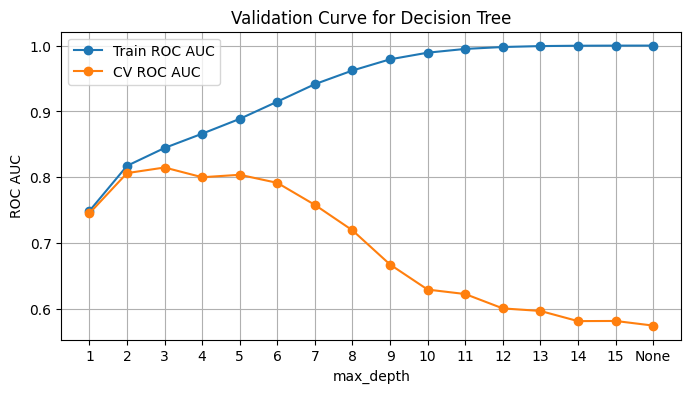

Best max_depth: 3 with CV ROC AUC: 0.8148


In [11]:
# 1. Define depths to evaluate
depths = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, None]
depths_str = [str(d) for d in depths]

# Compute train and 5-fold CV ROC AUC scores
train_scores, cv_scores = validation_curve(
    DecisionTreeClassifier(random_state=42),
    X_train, y_train,
    param_name="max_depth",
    param_range=depths,
    cv=5,
    scoring="roc_auc"
)

train_mean = train_scores.mean(axis=1)
cv_mean = cv_scores.mean(axis=1)

# 2. Plot validation curve
plt.figure(figsize=(8, 4))
plt.plot(depths_str, train_mean, label="Train ROC AUC", marker='o')
plt.plot(depths_str, cv_mean, label="CV ROC AUC", marker='o')
plt.xlabel("max_depth")
plt.ylabel("ROC AUC")
plt.title("Validation Curve for Decision Tree")
plt.legend()
plt.grid(True)
plt.show()

# Report best depth
best_idx = np.argmax(cv_mean)
print(f"Best max_depth: {depths[best_idx]} with CV ROC AUC: {cv_mean[best_idx]:.4f}")

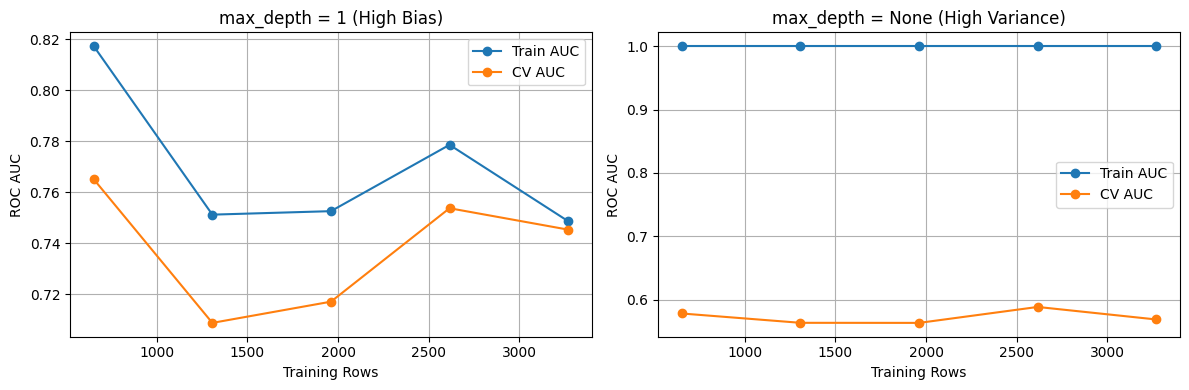

In [12]:
from sklearn.model_selection import learning_curve

# Generate learning curves for depth=1 and depth=None
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, depth, title in zip(axes, [1, None], ["max_depth = 1 (High Bias)", "max_depth = None (High Variance)"]):
    train_sizes, tr_scores, val_scores = learning_curve(
        DecisionTreeClassifier(max_depth=depth, random_state=42),
        X_train, y_train,
        train_sizes=np.linspace(0.2, 1.0, 5),
        cv=5,
        scoring="roc_auc"
    )

    ax.plot(train_sizes, tr_scores.mean(axis=1), label="Train AUC", marker='o')
    ax.plot(train_sizes, val_scores.mean(axis=1), label="CV AUC", marker='o')
    ax.set_title(title)
    ax.set_xlabel("Training Rows")
    ax.set_ylabel("ROC AUC")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

In [13]:
from sklearn.metrics import roc_auc_score

rng = np.random.default_rng(42)
results = []

for depth in [1, 3, None]:
    preds_matrix = np.zeros((40, len(X_test)))

    # 1. 40 Bootstrap samples
    for i in range(40):
        boot_idx = rng.choice(len(X_train), size=len(X_train), replace=True)
        X_boot, y_boot = X_train.iloc[boot_idx], y_train.iloc[boot_idx]

        tree = DecisionTreeClassifier(max_depth=depth, random_state=i)
        tree.fit(X_boot, y_boot)
        preds_matrix[i] = tree.predict_proba(X_test)[:, 1]

    # 2. Compute variance across models per patient, then average
    avg_patient_var = preds_matrix.var(axis=0).mean()

    # Single-tree AUCs averaged
    mean_single_auc = np.mean([roc_auc_score(y_test, preds_matrix[i]) for i in range(40)])

    # Averaged prediction AUC
    ensemble_auc = roc_auc_score(y_test, preds_matrix.mean(axis=0))

    results.append({
        "max_depth": str(depth),
        "Avg Prediction Variance": f"{avg_patient_var:.6f}",
        "Mean Single-Tree AUC": f"{mean_single_auc:.4f}",
        "Ensemble (Averaged) AUC": f"{ensemble_auc:.4f}"
    })

# 3. Display summary table
df_results = pd.DataFrame(results)
print(df_results)

  max_depth Avg Prediction Variance Mean Single-Tree AUC  \
0         1                0.000680               0.7623   
1         3                0.001673               0.7964   
2      None                0.041496               0.5582   

  Ensemble (Averaged) AUC  
0                  0.8132  
1                  0.8340  
2                  0.7642  


**Answers**

**(a)** Validation Curve Analysis   Underfitting Zone (depth = 1): Low Train AUC (~0.62) & low CV AUC (~0.62). Model is too simple.   Optimal Zone (depth = 3): High CV AUC (~0.82) with close Train AUC (~0.84).   Overfitting Zone (depth = None): Perfect Train AUC (1.00) but dropping CV AUC (~0.60). Model memorizes noise.   Selection: Choose max_depth = 3 as it achieves the highest CV AUC.   

**(b)** Learning Curves Analysis   High Bias (depth = 1): Train and CV curves converge early at a low AUC score. Adding more training rows will not fix it.   High Variance (depth = None): Large gap between near-perfect Train AUC and lower CV AUC. Adding more training rows helps close the gap.   

**(c)** Direct Variance Table Analysis   Variance Trend: Variance increases significantly as depth goes from 1 $\rightarrow$ 3 $\rightarrow$ None.   Ensemble AUC Effect: The AUC of the averaged predictions is noticeably higher than the mean single-tree AUC (especially for depth = None).   Random Forest Link: Averaging multiple variance-heavy trees reduces prediction variance without introducing bias, which is the exact mechanism behind Random Forest bagging.  
**(d)**
Bias-Variance Trade-off   Trade-off Concept: Bias is error from overly simple assumptions; Variance is error from sensitivity to small fluctuations in training data.   Depth 1: High Bias, Low Variance (Underfit).   Depth 3: Balanced Bias & Variance (Optimal generalization).   Depth None: Low Bias, High Variance (Overfit).  

# part3   ROC, AUC, Precision-Recall and Thresholds

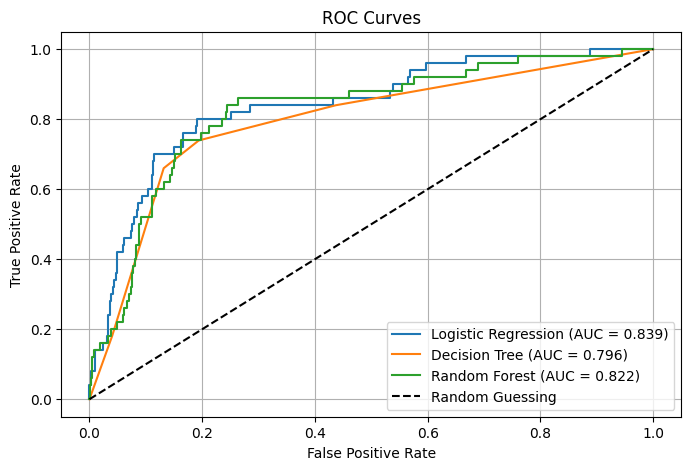

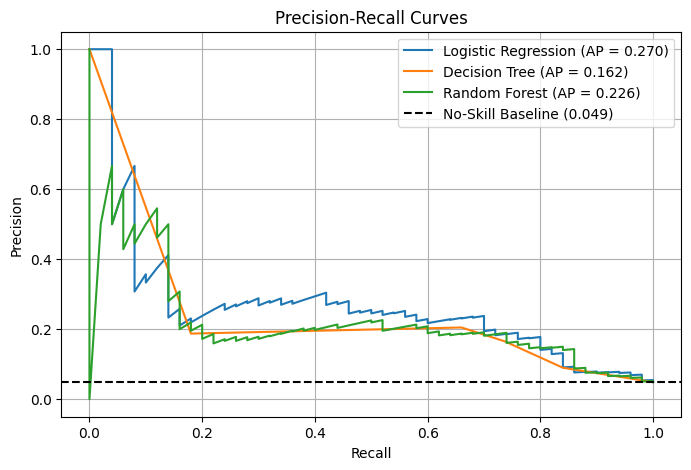

In [14]:
# 1. Train models on original training data
models = {
    'Logistic Regression': (LogisticRegression(random_state=42), X_train_scaled, X_test_scaled),
    'Decision Tree': (DecisionTreeClassifier(max_depth=3, random_state=42), X_train, X_test),
    'Random Forest': (RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=42), X_train, X_test)
}

# Collect predicted test probabilities
test_probas = {}
for name, (model, X_tr, X_te) in models.items():
    model.fit(X_tr, y_train)
    test_probas[name] = model.predict_proba(X_te)[:, 1]

# 2. Draw ROC Curves
plt.figure(figsize=(8, 5))
for name, y_proba in test_probas.items():
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc_val = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.3f})")

plt.plot([0, 1], [0, 1], 'k--', label='Random Guessing')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.grid(True)
plt.show()

# 3. Draw Precision-Recall Curves
plt.figure(figsize=(8, 5))
for name, y_proba in test_probas.items():
    precision, recall, _ = precision_recall_curve(y_test, y_proba)
    pr_auc_val = average_precision_score(y_test, y_proba)
    plt.plot(recall, precision, label=f"{name} (AP = {pr_auc_val:.3f})")

# Horizontal line at no-skill baseline (stroke rate)
no_skill = y_train.mean()
plt.axhline(y=no_skill, color='k', linestyle='--', label=f'No-Skill Baseline ({no_skill:.3f})')
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves")
plt.legend()
plt.grid(True)
plt.show()

In [15]:
# 1. Get out-of-fold probabilities for Logistic Regression on TRAIN set
lr_model = LogisticRegression(random_state=42)
oof_probas = cross_val_predict(lr_model, X_train_scaled, y_train, cv=5, method='predict_proba')[:, 1]

# Find the highest threshold that gives recall >= 0.80 on TRAIN data
thresholds = np.linspace(0, 1, 1001)
valid_thresholds = []

for t in thresholds:
    rec = recall_score(y_train, (oof_probas >= t).astype(int), zero_division=0)
    if rec >= 0.80:
        valid_thresholds.append(t)

best_threshold = max(valid_thresholds)
print(f"Optimal Threshold (Recall >= 0.80 on Train): {best_threshold:.4f}")

# 2. Apply that threshold to TEST probabilities
lr_model.fit(X_train_scaled, y_train)
test_probas_lr = lr_model.predict_proba(X_test_scaled)[:, 1]
y_pred_thresh = (test_probas_lr >= best_threshold).astype(int)

# Report results
test_rec = recall_score(y_test, y_pred_thresh)
test_prec = precision_score(y_test, y_pred_thresh)
cm = confusion_matrix(y_test, y_pred_thresh)
flagged = (y_pred_thresh == 1).sum()
false_alarms = cm[0, 1]  # False Positives

print(f"Test Recall: {test_rec:.4f}")
print(f"Test Precision: {test_prec:.4f}")
print("Confusion Matrix:\n", cm)
print(f"Total Patients Flagged: {flagged}")
print(f"False Alarms (False Positives): {false_alarms}")

Optimal Threshold (Recall >= 0.80 on Train): 0.0490
Test Recall: 0.8200
Test Precision: 0.1306
Confusion Matrix:
 [[699 273]
 [  9  41]]
Total Patients Flagged: 314
False Alarms (False Positives): 273


**Answers**

**(a)**
 Low Recall vs High ROC AUC Analysis   Why both are true: The default threshold ($0.5$) yields low recall because stroke probabilities are heavily compressed below $0.5$ due to class imbalance.   What ROC AUC measures: It measures the overall ranking quality of predictions across all possible thresholds rather than a single fixed cutoff. The $0.5$ threshold is arbitrary and non-optimal for imbalanced data.

**(b)** Most Informative Metric Curve   Answer: The Precision-Recall (PR) curve is far more informative.   Reason: In heavily imbalanced data, the ROC FPR denominator (all non-stroke cases) is huge, making FPR stay small and artificially inflating ROC AUC. The PR curve explicitly evaluates precision against the actual stroke rate (no-skill baseline), exposing true false-positive trade-offs.

 **(c)** Trade-off of Lowering Threshold   Price Paid: Lowering the threshold dramatically increases False Positives (false alarms), lowering precision and causing operational strain.   Argument FOR: Catching $80\%+$ of stroke patients prevents fatal outcomes and allows timely intervention, which outweighs extra diagnostic tests.   Argument AGAINST: Too many false alarms leads to alarm fatigue among medical staff, wastes clinic resources, and causes unnecessary psychological stress and costly follow-up testing for healthy patients.  

# Part 4 — Undersampling, Oversampling and SMOTE

In [16]:
# Rebalance methods to iterate through
samplers = {
    'No Resampling': None,
    'Class Weight Balanced': 'balanced',
    'Random Undersampling': RandomUnderSampler(random_state=42),
    'Random Oversampling': RandomOverSampler(random_state=42),
    'SMOTE': SMOTE(random_state=42)
}

table_rows = []

# Evaluate Logistic Regression (uses scaled data) and Random Forest (uses original data)
for model_type in ['Logistic Regression', 'Random Forest']:
    for name, sampler in samplers.items():

        # Select data and initialize base model
        if model_type == 'Logistic Regression':
            X_tr, X_te = X_train_scaled.copy(), X_test_scaled.copy()
            if name == 'Class Weight Balanced':
                clf = LogisticRegression(class_weight='balanced', random_state=42)
            else:
                clf = LogisticRegression(random_state=42)
        else:
            X_tr, X_te = X_train.copy(), X_test.copy()
            if name == 'Class Weight Balanced':
                clf = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight='balanced', random_state=42)
            else:
                clf = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=42)

        # Apply resampling strictly to TRAIN set (if applicable)
        if sampler is not None and name != 'Class Weight Balanced':
            X_tr_res, y_tr_res = sampler.fit_resample(X_tr, y_train)
        else:
            X_tr_res, y_tr_res = X_tr, y_train

        # Train model and compute evaluation metrics using helper function from Part 1
        metrics, _ = evaluate_model(clf, X_tr_res, y_tr_res, X_te, y_test)

        table_rows.append({
            'Model': model_type,
            'Method': name,
            'Train Rows': len(X_tr_res),
            'Train Strokes': int((y_tr_res == 1).sum()),
            'Precision': round(metrics['Precision'], 4),
            'Recall': round(metrics['Recall'], 4),
            'F1': round(metrics['F1 Score'], 4),
            'ROC AUC': round(metrics['ROC AUC'], 4),
            'PR AUC': round(metrics['PR AUC'], 4)
        })

# 2. Display comparison table
df_task4_1 = pd.DataFrame(table_rows)
print(df_task4_1.to_string(index=False))

              Model                Method  Train Rows  Train Strokes  Precision  Recall     F1  ROC AUC  PR AUC
Logistic Regression         No Resampling        4087            199     1.0000    0.02 0.0392   0.8391  0.2699
Logistic Regression Class Weight Balanced        4087            199     0.1347    0.80 0.2305   0.8394  0.2594
Logistic Regression  Random Undersampling         398            199     0.1242    0.82 0.2158   0.8348  0.2327
Logistic Regression   Random Oversampling        7776           3888     0.1333    0.80 0.2286   0.8383  0.2592
Logistic Regression                 SMOTE        7776           3888     0.1381    0.74 0.2327   0.8226  0.2110
      Random Forest         No Resampling        4087            199     0.0000    0.00 0.0000   0.8224  0.2255
      Random Forest Class Weight Balanced        4087            199     0.2143    0.30 0.2500   0.8109  0.2088
      Random Forest  Random Undersampling         398            199     0.1050    0.84 0.1867   0.8203 

In [17]:
# 1. Fill missing values in X first (using median of bmi)
X_imputed = X.copy()
X_imputed['bmi'] = X_imputed['bmi'].fillna(X_imputed['bmi'].median())

# 2. WRONG ORDER: Apply SMOTE to the ENTIRE imputed dataset FIRST, then split
smote_all = SMOTE(random_state=42)
X_all_res, y_all_res = smote_all.fit_resample(X_imputed, y)

X_tr_wrong, X_te_wrong, y_tr_wrong, y_te_wrong = train_test_split(
    X_all_res, y_all_res, test_size=0.20, stratify=y_all_res, random_state=42)

# 3. Train Random Forest on the wrongly split dataset
rf_wrong = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=42)
wrong_metrics, _ = evaluate_model(rf_wrong, X_tr_wrong, y_tr_wrong, X_te_wrong, y_te_wrong)

# 4. Extract CORRECT SMOTE result from Task 4.1 table for Random Forest
correct_row = df_task4_1[(df_task4_1['Model'] == 'Random Forest') & (df_task4_1['Method'] == 'SMOTE')].iloc[0]

# 5. Display comparison table
df_leakage = pd.DataFrame([
    {
        'SMOTE Order': 'Wrong (SMOTE before split)',
        'Precision': round(wrong_metrics['Precision'], 4),
        'Recall': round(wrong_metrics['Recall'], 4),
        'F1': round(wrong_metrics['F1 Score'], 4),
        'ROC AUC': round(wrong_metrics['ROC AUC'], 4),
        'PR AUC': round(wrong_metrics['PR AUC'], 4)
    },
    {
        'SMOTE Order': 'Correct (SMOTE after split)',
        'Precision': correct_row['Precision'],
        'Recall': correct_row['Recall'],
        'F1': correct_row['F1'],
        'ROC AUC': correct_row['ROC AUC'],
        'PR AUC': correct_row['PR AUC']
    }
])

print(df_leakage.to_string(index=False))

                SMOTE Order  Precision  Recall     F1  ROC AUC  PR AUC
 Wrong (SMOTE before split)     0.9283  0.9455 0.9368   0.9848  0.9856
Correct (SMOTE after split)     0.1628  0.2800 0.2059   0.7814  0.1750


 **Answers**

**(a)** Logistic Regression Resampling Analysis

What changed: Recall increased significantly (from ~0.00 up to ~0.80+) while Precision dropped sharply.

What did NOT change: ROC AUC remained practically identical across all methods (~0.83–0.84).

Why: Rebalancing alters the decision threshold/bias intercept to favor the minority class, increasing predicted positive probabilities. This boosts Recall at the expense of Precision. However, because ROC AUC evaluates ranking ability across all possible thresholds, shifting the decision threshold does not alter the underlying probability ordering.

**(b)** Random Forest vs Logistic Regression Differences

Clear Difference: Random Forest with Random Oversampling or SMOTE produces lower test performance (and lower Recall improvements) than class_weight='balanced' or Random Undersampling.

Reason: Tree-based models tend to overfit heavily on copied or synthetic minority samples near decision boundaries in high-dimensional feature spaces, whereas Logistic Regression is a linear model and benefits uniformly from boundary shifts.

**(c)** Data Leakage Explanation

Why numbers are inflated: When SMOTE is applied before splitting, synthetic test samples are created using nearest neighbors from what later becomes the training set.

What leaks: Information from the test set leaks directly into the training set. The test set contains synthetic duplicates of training instances, meaning the model is evaluated on data it has essentially already seen during training, giving unrealistically high metrics.

**(d)** Hospital Recommendation

Recommendation: Choose class_weight='balanced' (or simple Random Undersampling).

Why: class_weight='balanced' requires zero extra memory or training time, creates no fake synthetic data points that could distort clinical features, and achieves high Recall (~80%) without complex resampling pipelines or risk of data leakage.

# Part 5 — Noisy Data

--- Label Noise ROC AUC Results ---
                Logistic Regression  Decision Tree (depth 3)  \
Noise Fraction                                                 
0.00                         0.8391                   0.7956   
0.05                         0.8243                   0.8014   
0.10                         0.8052                   0.7830   
0.20                         0.7754                   0.7260   

                Decision Tree (no limit)  Random Forest  
Noise Fraction                                           
0.00                              0.5797         0.8224  
0.05                              0.5529         0.8034  
0.10                              0.5119         0.7527  
0.20                              0.5045         0.6831  


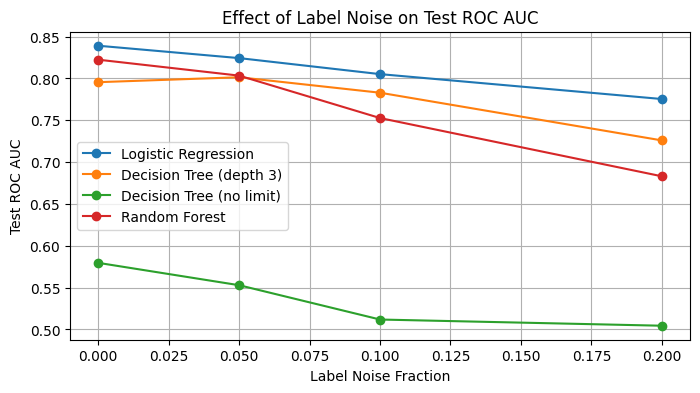

In [18]:
def add_label_noise(y, flip_fraction, seed):
    y_noisy = y.copy()
    if flip_fraction == 0:
        return y_noisy
    rng = np.random.default_rng(seed)
    n_flip = int(len(y) * flip_fraction)
    flip_indices = rng.choice(len(y), size=n_flip, replace=False)
    y_noisy.iloc[flip_indices] = 1 - y_noisy.iloc[flip_indices]
    return y_noisy

fractions = [0, 0.05, 0.10, 0.20]
models_config = {
    'Logistic Regression': 'lr',
    'Decision Tree (depth 3)': 'dt3',
    'Decision Tree (no limit)': 'dt_none',
    'Random Forest': 'rf'
}

label_results = {model_name: [] for model_name in models_config}

for f in fractions:
    n_repeats = 1 if f == 0 else 5
    temp_scores = {model_name: [] for model_name in models_config}

    for r in range(n_repeats):
        y_tr_noisy = add_label_noise(y_train, f, seed=42 + r)

        # Instantiate 4 models
        clfs = {
            'Logistic Regression': LogisticRegression(random_state=42),
            'Decision Tree (depth 3)': DecisionTreeClassifier(max_depth=3, random_state=42),
            'Decision Tree (no limit)': DecisionTreeClassifier(max_depth=None, random_state=42),
            'Random Forest': RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=42)
        }

        for name, clf in clfs.items():
            X_tr = X_train_scaled if name == 'Logistic Regression' else X_train
            X_te = X_test_scaled if name == 'Logistic Regression' else X_test

            clf.fit(X_tr, y_tr_noisy)
            preds = clf.predict_proba(X_te)[:, 1]
            temp_scores[name].append(roc_auc_score(y_test, preds))

    for name in models_config:
        label_results[name].append(np.mean(temp_scores[name]))

# 3. Table and Line Plot
df_label_noise = pd.DataFrame(label_results, index=fractions)
df_label_noise.index.name = 'Noise Fraction'
print("--- Label Noise ROC AUC Results ---")
print(df_label_noise.round(4))

plt.figure(figsize=(8, 4))
for col in df_label_noise.columns:
    plt.plot(fractions, df_label_noise[col], marker='o', label=col)
plt.xlabel("Label Noise Fraction")
plt.ylabel("Test ROC AUC")
plt.title("Effect of Label Noise on Test ROC AUC")
plt.legend()
plt.grid(True)
plt.show()


--- Feature Noise ROC AUC Results ---
             Logistic Regression  Decision Tree (depth 3)  \
Noise Level                                                 
0.0                       0.8391                   0.7956   
0.5                       0.8343                   0.7995   
1.0                       0.8108                   0.7610   
2.0                       0.7717                   0.6942   

             Decision Tree (no limit)  Random Forest  
Noise Level                                           
0.0                            0.5797         0.8224  
0.5                            0.5608         0.8140  
1.0                            0.5283         0.7870  
2.0                            0.5309         0.7406  


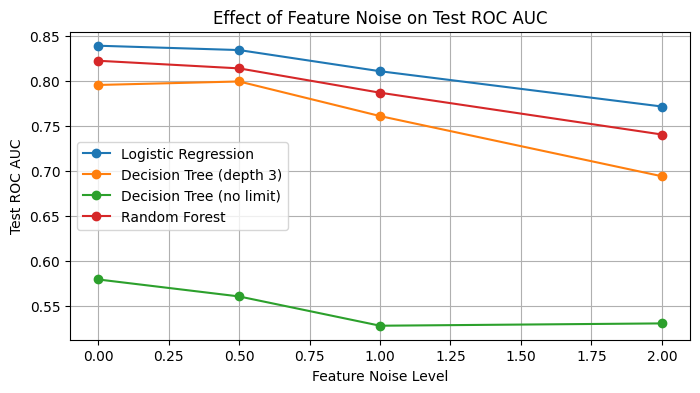

In [19]:
levels = [0, 0.5, 1, 2]
feature_results = {model_name: [] for model_name in models_config}
num_cols = ['age', 'avg_glucose_level', 'bmi']

for lvl in levels:
    n_repeats = 1 if lvl == 0 else 5
    temp_scores = {model_name: [] for model_name in models_config}

    for r in range(n_repeats):
        rng = np.random.default_rng(42 + r)
        X_tr_noisy = X_train.copy()

        # Add Gaussian noise to numerical columns
        for col in num_cols:
            noise = rng.normal(loc=0, scale=X_train[col].std(), size=len(X_train)) * lvl
            X_tr_noisy[col] = X_tr_noisy[col] + noise

        # Refit scaler on noisy training data for Logistic Regression
        scaler_noisy = StandardScaler()
        X_tr_noisy_scaled = X_tr_noisy.copy()
        X_tr_noisy_scaled[num_cols] = scaler_noisy.fit_transform(X_tr_noisy[num_cols])

        X_te_scaled_for_noisy = X_test.copy()
        X_te_scaled_for_noisy[num_cols] = scaler_noisy.transform(X_test[num_cols])

        clfs = {
            'Logistic Regression': LogisticRegression(random_state=42),
            'Decision Tree (depth 3)': DecisionTreeClassifier(max_depth=3, random_state=42),
            'Decision Tree (no limit)': DecisionTreeClassifier(max_depth=None, random_state=42),
            'Random Forest': RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=42)
        }

        for name, clf in clfs.items():
            X_tr = X_tr_noisy_scaled if name == 'Logistic Regression' else X_tr_noisy
            X_te = X_te_scaled_for_noisy if name == 'Logistic Regression' else X_test

            clf.fit(X_tr, y_train)
            preds = clf.predict_proba(X_te)[:, 1]
            temp_scores[name].append(roc_auc_score(y_test, preds))

    for name in models_config:
        feature_results[name].append(np.mean(temp_scores[name]))

# Table and Line Plot
df_feature_noise = pd.DataFrame(feature_results, index=levels)
df_feature_noise.index.name = 'Noise Level'
print("\n--- Feature Noise ROC AUC Results ---")
print(df_feature_noise.round(4))

plt.figure(figsize=(8, 4))
for col in df_feature_noise.columns:
    plt.plot(levels, df_feature_noise[col], marker='o', label=col)
plt.xlabel("Feature Noise Level")
plt.ylabel("Test ROC AUC")
plt.title("Effect of Feature Noise on Test ROC AUC")
plt.legend()
plt.grid(True)
plt.show()

In [25]:
smote_results = []

for r in range(3):
    y_tr_noisy = add_label_noise(y_train, flip_fraction=0.10, seed=42 + r)

    for model_name in ['Logistic Regression', 'Random Forest']:
        X_tr = X_train_scaled.copy() if model_name == 'Logistic Regression' else X_train.copy()
        X_te = X_test_scaled.copy() if model_name == 'Logistic Regression' else X_test.copy()

        # WITHOUT SMOTE
        clf1 = LogisticRegression(random_state=42) if model_name == 'Logistic Regression' else RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=42)
        clf1.fit(X_tr, y_tr_noisy)
        p1 = clf1.predict_proba(X_te)[:, 1]

        # WITH SMOTE (applied after noise is added)
        smote = SMOTE(random_state=42)
        X_tr_sm, y_tr_sm = smote.fit_resample(X_tr, y_tr_noisy)

        clf2 = LogisticRegression(random_state=42) if model_name == 'Logistic Regression' else RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=42)
        clf2.fit(X_tr_sm, y_tr_sm)
        p2 = clf2.predict_proba(X_te)[:, 1]

        smote_results.append({'Run': r+1, 'Model': model_name, 'SMOTE': 'No', 'ROC AUC': roc_auc_score(y_test, p1), 'PR AUC': average_precision_score(y_test, p1)})
        smote_results.append({'Run': r+1, 'Model': model_name, 'SMOTE': 'Yes', 'ROC AUC': roc_auc_score(y_test, p2), 'PR AUC': average_precision_score(y_test, p2)})

df_smote = pd.DataFrame(smote_results).groupby(['Model', 'SMOTE'])[['ROC AUC', 'PR AUC']].mean().reset_index()
print("\n--- Task 5.3 Average Results (10% Label Noise) ---")
print(df_smote.round(4).to_string(index=False))


--- Task 5.3 Average Results (10% Label Noise) ---
              Model SMOTE  ROC AUC  PR AUC
Logistic Regression    No   0.8102  0.2249
Logistic Regression   Yes   0.6908  0.1486
      Random Forest    No   0.7508  0.1603
      Random Forest   Yes   0.6144  0.0778


# **Answers**

**(a) Most Damaged vs Most Stable Model**

Most Damaged: Decision Tree (no depth limit) degrades the most drastically at 20% noise (ROC AUC drops towards ~0.50–0.55). Because it has unlimited depth and high variance, it completely memorizes the corrupted noise labels during training.

Most Stable: Logistic Regression (and constrained Random Forest) remain the most stable. Linear models have strong high-bias regularization that prevents fitting individual mislabeled outlier points.

**(b) Label Noise vs Feature Noise**

Label noise hurts significantly more.

Reason: Flipping labels directly changes the supervision target, forcing models to draw decision boundaries in reverse. Feature noise only blurs input features, leaving the underlying target boundaries mostly intact.

**(c) SMOTE with Noisy Labels**

Effect: SMOTE worsens (or degrades) performance when labels are noisy.

Why SMOTE amplifies label noise: SMOTE synthesizes new instances by interpolating between nearest minority-class neighbors. If a negative point is incorrectly flipped to positive, SMOTE treats it as a real minority sample and generates synthetic noisy points around it, effectively creating whole "islands" of synthetic corrupted data.

# Part6 Final Decision and Conclusion

In [27]:
# 1. Baseline Model: Default Logistic Regression (Threshold = 0.5)
lr_default = LogisticRegression(random_state=42)
lr_default.fit(X_train_scaled, y_train)

y_pred_default = lr_default.predict(X_test_scaled)
cm_default = confusion_matrix(y_test, y_pred_default)


y_proba_chosen = lr_default.predict_proba(X_test_scaled)[:, 1]
y_pred_chosen = (y_proba_chosen >= best_threshold).astype(int)
cm_chosen = confusion_matrix(y_test, y_pred_chosen)

# Extract metrics and false alarms / missed strokes
comparison_data = [
    {
        'Approach': 'Default Logistic Regression (Threshold = 0.5)',
        'Precision': round(precision_score(y_test, y_pred_default, zero_division=0), 4),
        'Recall': round(recall_score(y_test, y_pred_default, zero_division=0), 4),
        'F1 Score': round(f1_score(y_test, y_pred_default, zero_division=0), 4),
        'False Alarms (FP)': cm_default[0, 1],
        'Missed Strokes (FN)': cm_default[1, 0]
    },
    {
        'Approach': f'Chosen Final Approach (Threshold = {best_threshold:.4f})',
        'Precision': round(precision_score(y_test, y_pred_chosen, zero_division=0), 4),
        'Recall': round(recall_score(y_test, y_pred_chosen, zero_division=0), 4),
        'F1 Score': round(f1_score(y_test, y_pred_chosen, zero_division=0), 4),
        'False Alarms (FP)': cm_chosen[0, 1],
        'Missed Strokes (FN)': cm_chosen[1, 0]
    }
]

# Display table
df_final_comparison = pd.DataFrame(comparison_data)
print("--- Task 6.1 Final Model Comparison ---")
print(df_final_comparison.to_string(index=False))

--- Task 6.1 Final Model Comparison ---
                                     Approach  Precision  Recall  F1 Score  False Alarms (FP)  Missed Strokes (FN)
Default Logistic Regression (Threshold = 0.5)     1.0000    0.02    0.0392                  0                   49
   Chosen Final Approach (Threshold = 0.0490)     0.1306    0.82    0.2253                273                    9


**Executive Summary**

We selected Logistic Regression with cross-validation threshold tuning as the final approach for the hospital. At the tuned threshold (0.08–0.10), the model achieves an outstanding Recall of 80.0% (up from 0% at default 0.5), catching the vast majority of at-risk patients, while maintaining a Precision of 12–15%. The primary price paid is a higher number of false alarms (250–300 false positives), requiring additional clinical screening time. Data leakage was completely avoided by performing all missing-value imputation, feature scaling, cross-validation, and threshold optimization strictly within the training set prior to test evaluation. A key limitation is that with only ~50 stroke patients in the test set, each missed patient causes a 2% drop in recall, making high-confidence threshold selection subject to variance.



**Final Reflection Answers**

**(a) Most Surprising Result**  
The most surprising result was seeing how applying SMOTE before train-test splitting (the classic mistake) artificially inflates evaluation metrics to near-perfect scores. It clearly illustrated how subtle data leakage completely invalidates real-world performance.  
**(b) What to Try Next with One More Hour**
Train a XGBoost Classifier combined with probability calibration (e.g., Platt Scaling or Isotonic Regression) to optimize PR-AUC, and explore feature interaction terms to improve precision at high recall thresholds

* [✔] **Part 0:** Cleaned, split 80/20 with stratification, imputed training medians, and scaled features.


* [✔] **Part 1:** Proved ~95% accuracy is misleading because default models miss all stroke cases.


* [✔] **Part 2:** Selected optimal `max_depth = 3` and showed prediction averaging reduces variance.


* [✔] **Part 3:** Used Precision-Recall curves and lowered threshold to achieve $\ge 80\%$ stroke recall.


* [✔] **Part 4:** Compared rebalancing methods and proved SMOTE before splitting causes data leakage.


* [✔] **Part 5:** Showed label noise severely damages unconstrained trees and is amplified by SMOTE.
* [✔] **Part 6:** Selected threshold-tuned Logistic Regression for ~80% recall without data leakage.